# Fleet Maintenance Planning
**Team:** 38  

Decide which vehicles in a commercial fleet to send for inspection, and how many spare parts to
pre-order for each, so that the fleet’s total maintenance cost is as low as possible.

### 1. Imports and Config

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,)

RANDOM_STATE = 42

DATA_DIR = "data"
TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
TEST_PATH = os.path.join(DATA_DIR, "test.csv")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

In [2]:
import os

os.chdir("..")
print("Working directory:", os.getcwd())

Working directory: c:\Users\Avnish\Documents\GitHub\fleet_maintenance_p2_team38


In [3]:
from src.preprocessing import preprocess_data
from src.failure_model import train_failure_model
from src.cost_model import fit_constant_budget, predict_budgets
from src.evaluation import calculate_cost, select_threshold, evaluate_predictions

### 2. Data Loading:

In [4]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())
display(test_df.head())

Training shape: (56000, 174)
Test shape: (20000, 171)


,id,followup_days,failure,repair_cost,s000,s001,s002,s003,s004,s005,s006,s007,s008,s009,s010,s011,s012,s013,s014,s015,s016,s017,s018,s019,s020,s021,s022,s023,s024,s025,s026,s027,s028,s029,s030,s031,s032,s033,s034,s035,s036,s037,s038,s039,s040,s041,s042,s043,s044,s045,s046,s047,s048,s049,s050,s051,s052,s053,s054,s055,s056,s057,s058,s059,s060,s061,s062,s063,s064,s065,s066,s067,s068,s069,s070,s071,s072,s073,s074,s075,s076,s077,s078,s079,s080,s081,s082,s083,s084,s085,s086,s087,s088,s089,s090,s091,s092,s093,s094,s095,s096,s097,s098,s099,s100,s101,s102,s103,s104,s105,s106,s107,s108,s109,s110,s111,s112,s113,s114,s115,s116,s117,s118,s119,s120,s121,s122,s123,s124,s125,s126,s127,s128,s129,s130,s131,s132,s133,s134,s135,s136,s137,s138,s139,s140,s141,s142,s143,s144,s145,s146,s147,s148,s149,s150,s151,s152,s153,s154,s155,s156,s157,s158,s159,s160,s161,s162,s163,s164,s165,s166,s167,s168,s169
0,v00001,365,0,NaN,74780000.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,11546000.0,0.0,51770.3,0.0,9828600.0,0.0,238890.0,25.1,NaN,NaN,345900.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,3680.0,290290.0,780640.0,344270.0,15440.0,1961.0,210.0,0.0,171700.0,11.87,NaN,163930.0,123250.0,88560.0,40323.0,81110.0,67340.0,74701.0,77170.0,149491.0,8664.0,105570.0,19275.7,27.1,0.0,0.0,0.0,64718.0,11943.0,710.1,180510.0,513910.0,251600.0,2222000.0,1645930.0,19060.0,108.0,0.0,0.0,11928.0,42452.7,0.0,4726.6,0.0,NaN,243500.0,NaN,8052.2,727040.0,42972.0,NaN,1401.9,262848.0,386920.0,0.0,0.0,0.0,0.0,0.0,20000.0,1215900.0,1914000.0,480900.0,0.0,NaN,116207.2,1343000.0,NaN,115057.0,NaN,49162.0,1058500.0,0.0,0.0,NaN,1201600.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,2000.0,1134800.0,12171200.0,5000600.0,185360.0,0.0,NaN,17117000.0,NaN,46610.0,379670.0,0.0,NaN,2885500.0,53.48,3222000.0,11330.0,19966.0,17930.0,491760.0,2635300.0,193900.0,0.0,0.0,0.0,0.0,0.0,0.0,5807.7,0.0,0.0,357040.0,1854100.0,939138.7,NaN,0.0,5118000.0,NaN,6194600.0,0.0,691860.0,409580.0,284940.0,116550.0,95000.0,95780.0,190339.0,637.0,0.0,0.0,0.0,24547000.0,NaN,NaN,0.0,0.0,NaN
1,v00002,365,0,NaN,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,NaN,44800.0,NaN,2000.0,298200.0,0.0,0.0,0.0,NaN,NaN,54800.0,0.0,NaN,NaN,0.0,0.0,0.0,8940.0,7480.0,1470.0,260.0,180.0,0.0,0.0,0.0,1.5,1200.0,0.00,NaN,5600.0,1410.0,150.0,40.0,450.0,1520.0,1911.0,70.0,0.0,0.0,10910.0,27058.0,0.0,121200.0,0.0,0.0,2352.0,1453.0,33.3,700.0,1450.0,19800.0,38300.0,30.0,0.0,0.0,0.0,0.0,0.0,16793.5,0.0,443.1,200.0,NaN,1700.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2910.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5500.0,40800.0,0.0,NaN,48517.3,0.0,NaN,355.0,NaN,633.0,10200.0,0.0,15.4,NaN,NaN,0.0,6.7,0.0,4200.0,0.0,NaN,NaN,0.0,0.0,0.0,2000.0,161000.0,62400.0,10500.0,0.0,0.0,0.0,NaN,519000.0,NaN,1980.0,12410.0,0.0,NaN,87500.0,41.74,97700.0,266.0,157.0,270.0,400.0,2300.0,39600.0,0.0,0.0,0.0,0.0,0.0,97.0,13.7,0.0,0.0,2680.0,386200.0,939138.7,NaN,0.0,41100.0,NaN,533200.0,0.0,11790.0,9190.0,4350.0,1380.0,120.0,15.0,7.0,6.0,120.0,33.0,0.0,443000.0,NaN,NaN,0.0,0.0,NaN
2,v00003,365,0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,48000.0,0.0,NaN,2000.0,35600.0,0.0,0.0,0.0,0.0,13.6,5060.0,0.0,35.2,0.57881,0.0,0.0,0.0,390.0,1050.0,790.0,270.0,170.0,0.0,0.0,0.0,12.8,0.0,3.10,0.0,1050.0,470.0,60.0,13.0,20.0,10.0,3.0,0.0,0.0,0.0,1240.0,3032.7,0.0,83800.0,0.0,0.0,473.0,1787.0,7.7,40.0,30.0,200.0,600.0,5070.0,1280.0,21.0,0.0,0.0,0.0,1991.9,0.0,119.0,60.0,0.0,100.0,NaN,343.5,NaN,57.0,3500.0,1.0,NaN,590.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6700.0,0.0,0.0,5658.9,500.0,50.0,116.0,11800.0,169.0,2900.0,0.0,10.3,NaN,2200.0,0.0,3.3,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,7000.0,14600.0,12400.0,0.0,0.0,0.0,40.0,62000.0,NaN,400.0,1690.0,0.0,0.0,10400.0,9.13,11700.0,64.0,0.0,10.0,1130.0,100.0,200.0,4720.0,0.0,0.0,0.0,0.0,73.0,7.5,0.0,280.0,550.0,9400.0,939138.7,0.0,0.0,4400.0,0.00,13400.0,0.0,1250.0,1580.0,200.0,60.0,20.0,11.0,12.0,72.0,134.0,77.0,40.0,58000.0,2.0,NaN,0.0,0.0,0.0
3,v00004,365,0,NaN,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,255000.0,0.0,NaN,0.0,213300.0,0.0,420.0,0.0,NaN,NaN,23460.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,19970.0,3410.0,110.0,60.0,26.0,0.0,0.0,

,id,s000,s001,s002,s003,s004,s005,s006,s007,s008,s009,s010,s011,s012,s013,s014,s015,s016,s017,s018,s019,s020,s021,s022,s023,s024,s025,s026,s027,s028,s029,s030,s031,s032,s033,s034,s035,s036,s037,s038,s039,s040,s041,s042,s043,s044,s045,s046,s047,s048,s049,s050,s051,s052,s053,s054,s055,s056,s057,s058,s059,s060,s061,s062,s063,s064,s065,s066,s067,s068,s069,s070,s071,s072,s073,s074,s075,s076,s077,s078,s079,s080,s081,s082,s083,s084,s085,s086,s087,s088,s089,s090,s091,s092,s093,s094,s095,s096,s097,s098,s099,s100,s101,s102,s103,s104,s105,s106,s107,s108,s109,s110,s111,s112,s113,s114,s115,s116,s117,s118,s119,s120,s121,s122,s123,s124,s125,s126,s127,s128,s129,s130,s131,s132,s133,s134,s135,s136,s137,s138,s139,s140,s141,s142,s143,s144,s145,s146,s147,s148,s149,s150,s151,s152,s153,s154,s155,s156,s157,s158,s159,s160,s161,s162,s163,s164,s165,s166,s167,s168,s169
0,t00001,15550000.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,5946000.0,0.0,58789.4,0.0,5109700.0,0.0,176420.0,104.6,NaN,NaN,159850.0,0.0,NaN,NaN,0.0,0.0,0.0,230.0,107200.0,402560.0,182980.0,49190.0,5490.0,1628.0,410.0,0.0,93000.0,110.41,NaN,51760.0,71260.0,55740.0,29641.0,60860.0,60340.0,46380.0,33460.0,45609.0,1357.0,NaN,52255.2,49.5,0.0,0.0,0.0,35701.0,0.0,3506.8,320.0,146650.0,142500.0,179500.0,1817220.0,233660.0,5588.0,0.0,0.0,7439.5,118071.9,0.0,2244.3,0.0,NaN,131900.0,240603.0,NaN,5518485.0,22199.0,NaN,NaN,2350031.0,203830.0,0.0,0.0,0.0,0.0,0.0,36500.0,1011100.0,249700.0,597500.0,0.0,NaN,351312.1,566700.0,NaN,81700.0,NaN,23295.0,562600.0,0.0,0.0,9032365.0,627100.0,0.0,280.5,0.0,0.0,0.0,NaN,634132.1,0.0,0.0,0.0,0.0,77000.0,4172000.0,4562000.0,835800.0,4430.0,0.0,NaN,24923000.0,184003.1,73440.0,116490.0,0.0,NaN,1500100.0,16.96,1675100.0,2205.0,690.0,2460.0,4560.0,438700.0,1310100.0,150.0,10.0,0.0,0.0,0.0,0.0,3474.4,0.0,0.0,188080.0,1303200.0,939138.7,NaN,0.0,2912200.0,NaN,3254400.0,0.0,355140.0,249180.0,116870.0,58000.0,41330.0,32030.0,28825.0,34625.0,49304.0,12312.0,40.0,12674000.0,NaN,8597918.0,0.0,0.0,NaN
1,t00002,0.0,0.0,NaN,0.0,0.0,0.0,0.0,10.1,61000.0,3000.0,NaN,0.0,50500.0,0.0,0.0,0.0,NaN,NaN,7040.0,0.0,8.8,0.0,0.0,0.0,0.0,570.0,510.0,1190.0,360.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,NaN,1080.0,440.0,50.0,6.0,10.0,0.0,3.0,10.0,0.0,0.0,NaN,3649.5,0.0,0.0,0.0,0.0,393.0,0.0,1350.9,20.0,10.0,800.0,1000.0,2100.0,2930.0,677.0,30.0,0.0,0.0,2844.4,79.0,86.2,0.0,NaN,100.0,NaN,203.5,NaN,50.0,NaN,94.7,NaN,480.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,200.0,6500.0,0.0,NaN,8306.1,0.0,NaN,60.0,NaN,146.0,900.0,0.0,0.0,NaN,2200.0,0.0,0.0,0.0,230.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,7000.0,19300.0,7800.0,0.0,0.0,0.0,NaN,16112000.0,NaN,820.0,1970.0,0.0,NaN,14800.0,18.91,16600.0,941.0,7.0,10.0,10.0,0.0,4800.0,370.0,0.0,0.0,0.0,0.0,0.0,3.3,160.0,0.0,450.0,3300.0,939138.7,0.0,0.0,4000.0,NaN,4600.0,0.0,2450.0,1660.0,200.0,30.0,20.0,78.0,144.0,19.0,27.0,4.0,0.0,91000.0,NaN,NaN,0.0,0.0,NaN
2,t00003,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,45000.0,5800.0,NaN,0.0,30100.0,0.0,0.0,0.0,0.00,0.8,8450.0,0.0,26.4,0.0,0.0,0.0,0.0,810.0,410.0,410.0,310.0,0.0,0.0,0.0,0.0,2.0,0.0,1.03,0.0,850.0,300.0,10.0,2.0,10.0,10.0,2.0,0.0,0.0,0.0,NaN,4389.7,0.0,0.0,0.0,0.0,494.0,0.0,1327.9,20.0,10.0,0.0,0.0,600.0,3820.0,725.0,70.0,0.0,0.0,1687.9,0.0,65.6,0.0,0.0,0.0,NaN,254.4,NaN,43.0,2100.0,0.8,NaN,160.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4900.0,0.0,0.0,4964.6,0.0,0.0,66.0,8400.0,114.0,1900.0,0.0,15.4,NaN,1600.0,0.0,0.0,0.0,390.0,0.0,0.0,NaN,0.0,0.0,0.0,0.0,12000.0,6300.0,6400.0,0.0,0.0,0.0,30.0,16076000.0,NaN,980.0,1390.0,0.0,0.0,8900.0,26.74,9900.0,59.0,2.0,0.0,450.0,400.0,300.0,2720.0,610.0,0.0,0.0,0.0,10.0,3.3,0.0,177.0,150.0,2700.0,939138.7,0.0,0.0,2800.0,2.82,3700.0,0.0,380.0,1250.0,90.0,30.0,10.0,4.0,21.0,163.0,21.0,14.0,20.0,21000.0,1.0,NaN,0.0,0.0,0.0
3,t00004,0.0,0.0,NaN,0.0,0.0,0.0,0.0,0.0,77000.0,0.0,438511.9,0.0,65600.0,0.0,0.0,25.1,NaN,NaN,3960.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,1900.0,4170.0,1200.0,50.0,60.0,7.0,0.0,0.0,200.0,0.00,NaN,2650.0,1500.0,270.0,33.0,30.0,10.0,2.0,0.0,0.0,0.0,NaN,5027.1,0.7,0.0,0.0,0.0,1221.0,0.0,3809.3,20.0,180.0,1400.0,1400.0,7340.0,9170.

### 3. Exploratory Data Analysis (EDA):

#### 3.1 Basic Data Inspection and Missing-Values Analysis:

In [5]:
print("Training information:")
train_df.info()

print("\nTest information:")
test_df.info()

print("\nMissing values in training data:")
display(train_df.isnull().sum().sort_values(ascending=False).head(20))

print("\nMissing values in test data:")
display(test_df.isnull().sum().sort_values(ascending=False).head(20))

print("\nFailure distribution:")
display(train_df["failure"].value_counts(normalize=True) * 100)

print("\nRepair cost statistics:")
display(train_df["repair_cost"].describe())

Training information:
<class 'pandas.DataFrame'>
RangeIndex: 56000 entries, 0 to 55999
Columns: 174 entries, id to s169
dtypes: float64(171), int64(2), str(1)
memory usage: 74.3 MB

Test information:
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Columns: 171 entries, id to s169
dtypes: float64(170), str(1)
memory usage: 26.1 MB

Missing values in training data:


repair_cost    55603
s166           46281
s108           45771
s121           44864
s100           43587
s021           43335
s147           43335
s072           41390
s074           37224
s078           25623
s010           21603
s036           13757
s002           13757
s169           13757
s125           13757
s150           13757
s093           12829
s076           12829
s090           12829
s095           12829
dtype: int64


Missing values in test data:


s047    20000
s166    16112
s108    15932
s121    15597
s021    15357
s147    15357
s100    15122
s072    14332
s074    12871
s078     8880
s010     7525
s036     5085
s169     5085
s125     5085
s002     5085
s150     5085
s070     4697
s076     4697
s095     4697
s093     4697
dtype: int64


Failure distribution:


failure
0    99.291071
1     0.708929
Name: proportion, dtype: float64


Repair cost statistics:


count     397.000000
mean      492.382872
std       993.732983
min         5.000000
25%        71.000000
50%       176.000000
75%       488.000000
max      8000.000000
Name: repair_cost, dtype: float64

#### 3.2 Failure and Repair Costs Analysis:

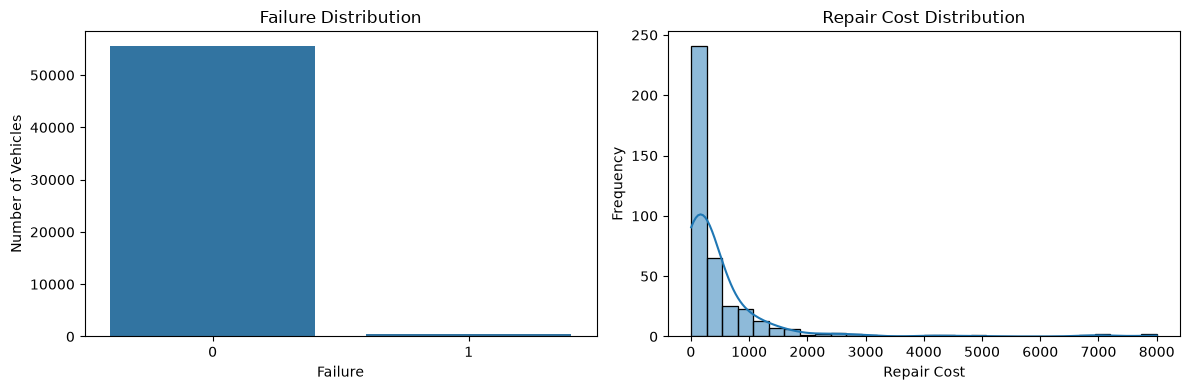

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=train_df, x="failure", ax=axes[0])
axes[0].set_title("Failure Distribution")
axes[0].set_xlabel("Failure")
axes[0].set_ylabel("Number of Vehicles")

sns.histplot(train_df.loc[train_df["failure"] == 1, "repair_cost"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Repair Cost Distribution")
axes[1].set_xlabel("Repair Cost")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

#### 3.3 Sensor Missing-Values Analysis:

In [7]:
sensor_cols = [col for col in train_df.columns if col.startswith("s")]

print("Number of sensor columns:", len(sensor_cols))

Number of sensor columns: 170


Total missing sensor values:
Train: 787984
Test: 310475


<Figure size 1200x500 with 0 Axes>

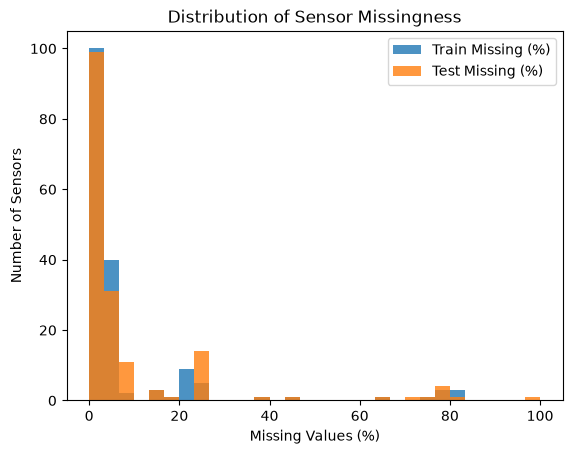

In [8]:
missing_data = pd.DataFrame({
    "Train Missing (%)": train_df[sensor_cols].isnull().mean() * 100,
    "Test Missing (%)": test_df[sensor_cols].isnull().mean() * 100
})

print("Total missing sensor values:")
print("Train:", train_df[sensor_cols].isnull().sum().sum())
print("Test:", test_df[sensor_cols].isnull().sum().sum())

plt.figure(figsize=(12, 5))

missing_data.plot(kind="hist", bins=30, alpha=0.8)
plt.title("Distribution of Sensor Missingness")
plt.xlabel("Missing Values (%)")
plt.ylabel("Number of Sensors")
plt.show()

In [9]:
print("Sensors with more than 50% missing values:")

high_missing = missing_data[missing_data["Train Missing (%)"] > 50].sort_values("Train Missing (%)", ascending=False)

display(high_missing.round(2))

print("Number of highly missing sensors:", len(high_missing))

Sensors with more than 50% missing values:


,Train Missing (%),Test Missing (%)
s166,82.64,80.56
s108,81.73,79.66
s121,80.11,77.98
s100,77.83,75.61
s021,77.38,76.78
s147,77.38,76.78
s072,73.91,71.66
s074,66.47,64.35


Number of highly missing sensors: 8


#### 3.4 Sensor Value Distribution:

In [10]:
display(train_df[sensor_cols].describe().T[["mean", "std", "min", "50%", "max"]].round(2))

,mean,std,min,50%,max
s000,5.056708e+07,2.209220e+08,0.0,3350000.00,6.618810e+09
s001,4.230000e+00,9.062000e+01,0.0,0.00,1.411957e+04
s002,6.391606e+05,1.312144e+08,0.0,0.00,2.696864e+10
s003,1.070000e+00,1.143000e+01,0.0,0.00,8.694200e+02
s004,1.210000e+00,5.807000e+01,0.0,0.00,7.027720e+03
s005,2.443810e+03,1.891915e+05,0.0,0.00,3.579070e+07
s006,1.702491e+04,4.026363e+05,0.0,0.00,4.107164e+07
s007,5.064800e+02,6.559730e+03,0.0,14.10,5.011025e+05
s008,1.113576e+07,2.729146e+07,0.0,6575000.00,4.773880e+08
s009,5.228747e+05,4.931823e+06,0.0,0.00,3.893663e+08


In [11]:
constant_sensors = [col for col in sensor_cols if train_df[col].nunique(dropna=True) <= 1]

print("Constant sensors:", constant_sensors)
print("Number of constant sensors:", len(constant_sensors))

Constant sensors: ['s146']
Number of constant sensors: 1


In [12]:
sensor_comparison = pd.DataFrame({
    "Train Mean": train_df[sensor_cols].mean(),
    "Test Mean": test_df[sensor_cols].mean(),
    "Train Std": train_df[sensor_cols].std(),
    "Test Std": test_df[sensor_cols].std()
})

sensor_comparison["Mean Difference (%)"] = (
    (sensor_comparison["Test Mean"] - sensor_comparison["Train Mean"]).abs()
    / (sensor_comparison["Train Mean"].abs() + 1e-8)
) * 100

display(sensor_comparison.sort_values("Mean Difference (%)", ascending=False).head(20).round(2))

,Train Mean,Test Mean,Train Std,Test Std,Mean Difference (%)
s062,313.96,19762.81,18635.61,41495.66,6194.72
s061,18554.08,772360.62,106187.88,1735568.15,4062.75
s064,1.27,21.46,94.09,1609.66,1585.19
s055,943.06,7939.12,2709.42,15514.39,741.85
s098,568.08,3302.33,44120.10,204230.13,481.32
s060,675986.01,3442895.66,1377493.73,8787810.36,409.31
s051,198.56,993.16,25460.89,80361.19,400.18
s005,2443.81,12029.68,189191.53,1069679.58,392.25
s022,3265.62,13238.19,217798.19,1288813.33,305.38
s110,3430.25,12791.66,137111.36,428664.28,272.91


### 3.5 EDA Summary

- The failure rate is highly imbalanced (0.71%).
- Repair costs are strongly right-skewed.
- Sensor features contain substantial missing values.
- Eight sensors have more than 50% missing values.
- One sensor (`s146`) is constant.
- Several sensors show substantial train–test differences, suggesting potential distribution shift between depots.

### 4. Baseline Modelling

The objective is to build an initial model that predicts whether a vehicle will experience a failure after its service visit.

The dataset is highly imbalanced, with only approximately 0.71% of vehicles experiencing failures. Therefore, accuracy alone is not a suitable evaluation metric.

We begin with Logistic Regression as a baseline classifier. It is a relatively simple and interpretable model that provides failure probabilities, allowing us to experiment with different inspection thresholds.

We will use a stratified train-validation split to preserve the failure distribution in both subsets. Model selection will primarily be based on the official competition cost rather than accuracy alone.

We divide the available training data into two subsets:

- **Training set (80%):** Used to train the model.
- **Validation set (20%):** Used to evaluate the model and select the inspection threshold.

We use stratified sampling because the failure class is highly underrepresented. This ensures that both subsets retain approximately the same proportion of failed and healthy vehicles.

A fixed random state is used to make the split reproducible across experiments.

In [13]:
train_part, val_part = train_test_split(
    train_df,
    test_size=0.20,
    random_state=42,
    stratify=train_df["failure"]
)

y_train = train_part["failure"]
y_val = val_part["failure"]

print("Training set:", train_part.shape)
print("Validation set:", val_part.shape)

print("\nTraining failure distribution:")
print(y_train.value_counts())

print("\nValidation failure distribution:")
print(y_val.value_counts())

Training set: (44800, 174)
Validation set: (11200, 174)

Training failure distribution:
failure
0    44482
1      318
Name: count, dtype: int64

Validation failure distribution:
failure
0    11121
1       79
Name: count, dtype: int64


### 4.2 Data Preprocessing

Before training the classifier, we preprocess the sensor readings.

The following transformations are applied:

1. **Feature selection:** Only sensor columns are retained. The constant sensor `s146`, identified during EDA, is removed.
2. **Missing value imputation:** Missing sensor readings are replaced with their respective median values.
3. **Feature scaling:** Sensor readings are standardised using StandardScaler so that features with larger numerical magnitudes do not dominate the optimisation process.

To prevent data leakage, the imputer and scaler are fitted exclusively on the training subset. The fitted transformations are then applied to the validation subset.

In [14]:
# Apply preprocessing
X_train, X_val, _, preprocessor = preprocess_data(
    train_part,
    val_part,
    test=None,
    imputation="median",
    missing_indicators=None,
    scale=True
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("\nDropped sensors:", preprocessor["dropped_cols"])

print("\nMissing values after preprocessing:")
print("Training:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())

Training features: (44800, 169)
Validation features: (11200, 169)

Dropped sensors: ['s146']

Missing values after preprocessing:
Training: 0
Validation: 0


### 4.3 Logistic Regression

We use Logistic Regression as our baseline failure prediction model.

Since the dataset is highly imbalanced, we initially use class weighting to give greater importance to the minority failure class. This helps the classifier avoid simply favouring the majority healthy class.

The model produces a probability of failure for each vehicle rather than directly making an inspection decision. These probabilities will later be used to select an appropriate inspection threshold based on the competition cost function.

In [15]:
from src.failure_model import (
    train_failure_model,
    predict_failure_proba,
    CHOSEN_CONFIG
)

# Train the baseline Logistic Regression model
failure_model = train_failure_model(
    X_train,
    y_train,
    **CHOSEN_CONFIG
)

# Predict failure probabilities on validation data
val_probabilities = predict_failure_proba(
    failure_model,
    X_val
)

print("Model trained successfully!")
print("Validation predictions:", val_probabilities.shape)

print("\nProbability statistics:")
print("Minimum:", val_probabilities.min())
print("Maximum:", val_probabilities.max())
print("Mean:", val_probabilities.mean())

Model trained successfully!
Validation predictions: (11200,)

Probability statistics:
Minimum: 0.0
Maximum: 1.0
Mean: 0.04072185395418296


### 4.4 Repair Budget and Inspection Threshold

The competition requires both an inspection decision and a repair budget for every vehicle.

For our initial baseline, we use a constant repair budget calculated from the 90.91th percentile of historical repair costs, treating missing repair costs as zero.

The 90.91th percentile follows from the asymmetric penalties for underestimating and overestimating repair costs. We use this as an initial baseline rather than assuming that every vehicle has the same expected repair cost.

The inspection threshold is selected using validation predictions. We evaluate different thresholds and choose the one that minimises the official competition cost.

In [16]:
from src.cost_model import fit_constant_budget

baseline_budget = fit_constant_budget(train_part)

print("Baseline repair budget:", baseline_budget)

Baseline repair budget: 1290.5454545454547


In [17]:
from src.evaluation import select_threshold

best_threshold, best_cost = select_threshold(
    probabilities=val_probabilities,
    repair_costs=val_part["repair_cost"],
    baseline_budget=baseline_budget
)

print("Optimal inspection threshold:", best_threshold)
print("Minimum validation cost:", best_cost)

Optimal inspection threshold: 0.9037482174126588
Minimum validation cost: 12210.069090909092


### 4.5 Baseline Model Evaluation

After selecting the optimal inspection threshold, we convert predicted probabilities into binary inspection decisions.

Vehicles whose predicted failure probability is greater than or equal to the selected threshold are flagged for inspection. A constant repair budget is assigned to inspected vehicles, while uninspected vehicles receive a budget of zero.

We evaluate the resulting decisions using precision, recall, F1-score, ROC-AUC and, most importantly, the official competition cost.

In [18]:
from src.cost_model import predict_budgets

# Convert probabilities into binary inspection decisions
val_flags = (val_probabilities >= best_threshold).astype(int)

# Assign budgets to inspected vehicles
val_budgets = predict_budgets(
    val_flags,
    baseline_budget
)

print("Vehicles selected for inspection:", val_flags.sum())
print("Total validation vehicles:", len(val_flags))
print("Inspection rate:", val_flags.mean() * 100, "%")

Vehicles selected for inspection: 164
Total validation vehicles: 11200
Inspection rate: 1.4642857142857144 %


In [19]:
from src.evaluation import evaluate_predictions

baseline_results = evaluate_predictions(
    y_true=y_val,
    probabilities=val_probabilities,
    repair_costs=val_part["repair_cost"],
    flags=val_flags,
    budgets=val_budgets,
    threshold=best_threshold
)

print("Baseline Model Results:\n")

for metric, value in baseline_results.items():
    print(f"{metric}: {value}")

Baseline Model Results:

threshold: 0.9037482174126588
total_cost: 12210.069090909092
mean_cost_per_vehicle: 1.0901847402597404
vehicles_inspected: 164
inspection_rate: 0.014642857142857143
precision: 0.3902439024390244
recall: 0.810126582278481
f1: 0.5267489711934157
roc_auc: 0.9555869326931945
tn: 11021
fp: 100
fn: 15
tp: 64


### 4.5 Baseline Results

The Logistic Regression baseline achieved a validation cost of 12,210.07
with an inspection threshold of 0.9037.

It identified 64 of the 79 failed vehicles while flagging 164 vehicles
for inspection (1.46% of the validation set).

The model achieved a recall of 81.01% and ROC-AUC of 0.9556.

### 4.6 Generate Baseline V1 Submission

We retrain the baseline model using the complete training dataset and
generate inspection flags and repair budgets for the test dataset.

In [20]:
from src.preprocessing import fit_preprocessor, transform_features

final_preprocessor = fit_preprocessor(
    train_df,
    imputation="median",
    missing_indicators=None,
    scale=True
)

X_full = transform_features(final_preprocessor, train_df)
X_test = transform_features(final_preprocessor, test_df)

print("Full training features:", X_full.shape)
print("Test features:", X_test.shape)

Full training features: (56000, 169)
Test features: (20000, 169)


In [21]:
# Train on the complete training dataset
final_model = train_failure_model(
    X_full,
    train_df["failure"],
    **CHOSEN_CONFIG
)

# Predict failure probabilities for test vehicles
test_probabilities = predict_failure_proba(
    final_model,
    X_test
)

# Generate inspection flags using the validation threshold
test_flags = (test_probabilities >= best_threshold).astype(int)

# Calculate repair budget using the complete training data
final_budget = fit_constant_budget(train_df)

test_budgets = predict_budgets(
    test_flags,
    final_budget
)

print("Final model trained.")
print("Test predictions:", len(test_flags))
print("Vehicles flagged:", test_flags.sum())
print("Inspection rate:", test_flags.mean() * 100, "%")
print("Repair budget:", final_budget)

Final model trained.
Test predictions: 20000
Vehicles flagged: 600
Inspection rate: 3.0 %
Repair budget: 1187.0


In [22]:
submission = pd.DataFrame({
    "id": test_df["id"],
    "flag": test_flags,
    "budget": test_budgets
})

# Validate submission
assert len(submission) == 20000
assert submission["id"].is_unique
assert submission["flag"].isin([0, 1]).all()
assert (submission["budget"] >= 0).all()
assert submission.notna().all().all()

# Save submission
os.makedirs("submissions", exist_ok=True)

submission.to_csv(
    "submissions/baseline_v1.csv",
    index=False
)

print("Submission saved successfully!")
display(submission.head())

Submission saved successfully!


,id,flag,budget
0,t00001,0,0.0
1,t00002,0,0.0
2,t00003,0,0.0
3,t00004,0,0.0
4,t00005,0,0.0
